### Lisa rennt – Lösung Schritt für Schritt

*37. Bundeswettbewerb Informatik (2018/2019), 2. Runde, Aufgabe 1*

Lisa schläft gern, besonders morgens. So schafft sie es nicht immer, rechtzeitig von daheim loszugehen, um an der Haltestelle zu sein,
wenn der Bus um 7.30 Uhr von dort abfährt. Zum Glück kennt sie der Busfahrer, und er nimmt sie auch mit, falls sie irgendwo am Rand der
schnurgeraden Landstraße steht, wenn der Bus dort vorbeikommt. Da der Bus nur 30 km/h fährt und sie selbst flotte 15 km/h über eine
beträchtliche Strecke schafft, kann sie durch geschicktes Querfeldeinlaufen etwas Zeit herausschlagen.

Dabei muss sie allerdings Hindernisse wie Baustellen und Tümpel umlaufen. Heute will sie es endlich mal genau wissen: Was ist der
letztmögliche Zeitpunkt, an dem sie ihr Haus spätestens verlassen muss, um den Bus irgendwo gerade noch zu erreichen? Welche Route soll
sie dabei einschlagen?

Lisa wünscht sich ein Programm, das ihr diese Frage beantwortet. Hierfür überlegt sie sich zuerst, wie sie laufen würde, wenn es keine
Hindernisse gäbe.

#### Aufgabe

Schreibe ein Programm, das das Problem allgemein löst. Als Eingabe erhält das Programm die Koordinaten von Lisas Haus sowie der als
Polygone modellierten Hindernisse. Dabei wird ein Koordinatensystem zugrunde gelegt, in dem der Bus die y-Achse abfährt, die
Haltestelle am Punkt (0,0) ist und alle Längen in Metern angegeben werden.

In der Abbildung (auf dem Aufgabenblatt) siehst du für ein Beispiel eine mögliche Route an verschiedenen Hindernissen vorbei von Lisas
Haus zur Landstraße, die aber offensichtlich nicht besonders gut ist. Wende dein Programm auf alle Beispiele an, die du auf den
BWINF-Webseiten findest; das Datenformat ist dort erläutert. Dokumentiere die Ergebnisse.

#### Beispieldaten

Im Ordner `beispieldaten` stehen `lisarennt1.txt` bis `lisarennt5.txt` (dazu je eine SVG-Zeichnung). Die Formatbeschreibung ist nicht
mehr erhalten; aus den Dateien liest man ab: Zeile 1 enthält die Zahl der Hindernisse, danach steht jedes Hindernis in einer Zeile,
zuerst die Zahl `k` seiner Ecken, dann `k` Paare `x y`. Die letzte Zeile enthält Lisas Haus. Alle Koordinaten sind ganze Zahlen.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Zeit rückwärts rechnen:** Lisa interessiert nicht, wie lange sie läuft, sondern wie spät sie losgehen darf. Das hängt vom
  Unterschied zwischen ihrer Laufzeit und der Fahrzeit des Busses bis zum Treffpunkt ab.
- **Kürzeste Wege um Hindernisse:** Ein kürzester Weg um Vielecke herum besteht aus geraden Stücken, die nur an Ecken der Hindernisse
  abknicken (ein Gummiband, das man straff zieht, legt sich genauso um die Ecken).
- **Sichtbarkeitsgraph:** Die Knoten sind Lisas Haus und alle Ecken der Hindernisse. Zwei Knoten sind verbunden, wenn die gerade
  Strecke zwischen ihnen durch kein Hindernis führt („sie sehen sich“).
- **Dijkstra-Algorithmus** für kürzeste Wege in einem Graphen mit Kantenlängen.
- **Geometrie mit dem Kreuzprodukt:** Das Vorzeichen von `(a - o) × (b - o)` sagt, ob `b` links oder rechts der Richtung von `o` nach
  `a` liegt. Damit prüft man, ob sich zwei Strecken kreuzen. Ob ein Punkt in einem Vieleck liegt, prüft man mit einem **Strahl**:
  Man zählt, wie oft ein Strahl vom Punkt nach rechts den Rand kreuzt (ungerade Anzahl: innen).
- **Toleranz bei Kommazahlen:** Lisa darf am Rand der Hindernisse entlanglaufen. Ob ein Punkt genau auf dem Rand liegt, kann man mit
  Kommazahlen nicht exakt prüfen. Wir vergleichen darum mit einer kleinen Toleranz `EPS`.

**Nützliche Funktionen und Bibliotheken**
- `math.dist(p, q)` (Abstand zweier Punkte), `math.tan`, `math.atan`, `math.radians`, `math.degrees`, `math.inf`.
- `heapq.heappush` und `heapq.heappop` für die Warteschlange von Dijkstra: `heappop` gibt immer das kleinste Element zurück.
- `matplotlib` mit `matplotlib.patches.Polygon` zum Zeichnen der Hindernisse und Wege.

## Die Idee in Worten

1. **Der Verlust:** Lisa läuft zu einem Punkt `(0, y)` der Straße. Dafür braucht sie die Laufzeit `Weglänge / 15 km/h`. Der Bus
   braucht von der Haltestelle bis dorthin `y / 30 km/h` und ist also um `7:30 Uhr + Fahrzeit` dort. Lisa muss spätestens um
   `7:30 Uhr - (Laufzeit - Fahrzeit)` losgehen. Den Unterschied `Laufzeit - Fahrzeit` nennen wir **Verlust**; er soll möglichst klein
   werden.
2. **Ohne Hindernisse** läuft Lisa geradeaus zur Straße, aber nicht senkrecht, sondern schräg in Fahrtrichtung des Busses. Durch
   Probieren finden wir den besten Winkel: **30°** gegen die Senkrechte zur Straße.
3. **Mit Hindernissen** läuft Lisa auf geraden Stücken von Ecke zu Ecke und vom letzten Knoten unter 30° zur Straße. Wir bauen den
   Sichtbarkeitsgraphen, geben jedem Knoten eine **Endkante** zur Straße (wenn die 30°-Strecke frei ist) und suchen mit Dijkstra den
   Weg mit dem kleinsten Verlust.
4. **Probe:** Ein Schiedsrichter prüft die Wege mit vielen Stichproben, und ein Raster aller Straßenpunkte zeigt, dass kein anderer
   Winkel besser ist.

## Schritt 1: Einlesen und Zeichnen

Ein Punkt ist ein Tupel `(x, y)`, ein Hindernis die Liste seiner Ecken. `lies` liest alle Zahlen der Datei auf einmal und geht sie mit
einem Zeiger `pos` durch. `zeichne` malt die Straße (die y-Achse), die Haltestelle, die Hindernisse (mit ihren Nummern `P1`, `P2`, …),
Lisas Haus und, wenn angegeben, einen Weg und einen Graphen; die brauchen wir später.

lisarennt1.txt: Haus (633, 189),  1 Hindernisse mit zusammen  3 Ecken
lisarennt2.txt: Haus (633, 189),  3 Hindernisse mit zusammen 14 Ecken
lisarennt3.txt: Haus (479, 168),  8 Hindernisse mit zusammen 50 Ecken
lisarennt4.txt: Haus (856, 270), 11 Hindernisse mit zusammen 56 Ecken
lisarennt5.txt: Haus (621, 162), 12 Hindernisse mit zusammen 62 Ecken


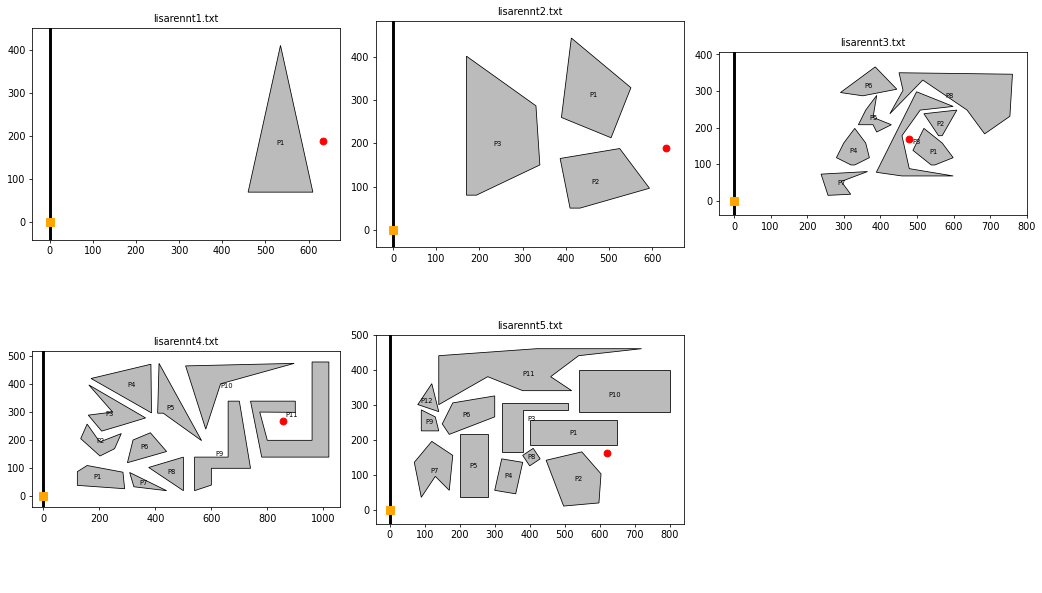

In [ ]:
import math
import heapq
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon


def datei(nr):
    return 'beispieldaten/lisarennt%d.txt' % nr


def lies(dateiname):
    with open(dateiname, encoding='utf-8') as f:
        zahlen = [int(z) for z in f.read().split()]
    hindernisse = []
    pos = 1
    for i in range(zahlen[0]):
        k = zahlen[pos]                       # Zahl der Ecken, dann k Paare x y
        ecken = []
        for j in range(k):
            ecken.append((zahlen[pos + 1 + 2 * j], zahlen[pos + 2 + 2 * j]))
        hindernisse.append(ecken)
        pos = pos + 1 + 2 * k
    haus = (zahlen[pos], zahlen[pos + 1])
    return haus, hindernisse


def zeichne(achse, haus, hindernisse, titel, punkte=None, graph=None):
    xs = [haus[0]] + [p[0] for h in hindernisse for p in h]
    ys = [haus[1], 0] + [p[1] for h in hindernisse for p in h]
    if graph is not None:                     # graph = (knoten, nachbarn, ende)
        knoten, nachbarn, ende = graph
        for i in range(len(knoten)):
            for j, dauer in nachbarn[i]:
                if i < j:
                    achse.plot([knoten[i][0], knoten[j][0]], [knoten[i][1], knoten[j][1]], color='#88aadd', linewidth=0.6)
        for i in ende:
            q = zielpunkt(knoten[i])
            achse.plot([knoten[i][0], q[0]], [knoten[i][1], q[1]], color='green', linewidth=0.6, linestyle='--')
            ys.append(q[1])
    for i in range(len(hindernisse)):
        achse.add_patch(Polygon(hindernisse[i], closed=True, facecolor='#bbbbbb', edgecolor='black', linewidth=0.8))
        mx = sum(p[0] for p in hindernisse[i]) / len(hindernisse[i])
        my = sum(p[1] for p in hindernisse[i]) / len(hindernisse[i])
        achse.text(mx, my, 'P%d' % (i + 1), ha='center', va='center', fontsize=7)
    if punkte is not None:
        achse.plot([p[0] for p in punkte], [p[1] for p in punkte], color='red', linewidth=2)
        ys.append(punkte[-1][1])
    achse.axvline(0, color='black', linewidth=3)                  # die Straße
    achse.plot([0], [0], 's', color='orange', markersize=8)        # die Haltestelle
    achse.plot([haus[0]], [haus[1]], 'o', color='red', markersize=7)
    achse.set_xlim(-40, max(xs) + 40)
    achse.set_ylim(min(ys) - 40, max(ys) + 40)
    achse.set_aspect('equal')
    achse.set_title(titel, fontsize=10)


beispiele = {}
for nr in range(1, 6):
    beispiele[nr] = lies(datei(nr))
    haus, hindernisse = beispiele[nr]
    print('lisarennt%d.txt: Haus %s, %2d Hindernisse mit zusammen %2d Ecken' %
          (nr, haus, len(hindernisse), sum(len(h) for h in hindernisse)))

fig, achsen = plt.subplots(2, 3, figsize=(15, 9))
for nr in range(1, 6):
    zeichne(achsen[(nr - 1) // 3][(nr - 1) % 3], beispiele[nr][0], beispiele[nr][1], 'lisarennt%d.txt' % nr)
achsen[1][2].axis('off')
plt.tight_layout()
plt.show()

Die Straße ist der schwarze senkrechte Strich links, das orange Quadrat die Haltestelle, der rote Punkt Lisas Haus. Der Bus fährt
nach oben. Alle Koordinaten sind positiv: Alles liegt rechts der Straße und oberhalb der Haltestelle.

Zwei Dinge setzen wir voraus, wie die Lösungshinweise: Lisa ist ein Punkt und darf am Rand der Hindernisse entlanglaufen (nur das
Innere ist verboten), und die Hindernisse überschneiden und berühren sich nicht. Das Zweite prüfen wir in Schritt 3.

## Schritt 2: Ohne Hindernisse – wohin soll Lisa laufen?

Lisa schafft 15 km/h, das sind 15000 m in 3600 s, also etwa 4,17 m/s; der Bus schafft das Doppelte. `verlust_direkt(p, y)` ist der
Verlust, wenn Lisa von `p` geradeaus zum Straßenpunkt `(0, y)` läuft. Wir probieren für das Haus aus `lisarennt1.txt` alle ganzen `y`
von 0 bis 2000 durch.

In [ ]:
V_LISA = 15 / 3.6          # Meter pro Sekunde
V_BUS = 30 / 3.6


def verlust_direkt(p, y):
    """Lisa läuft von p geradeaus nach (0, y): ihre Laufzeit minus die Fahrzeit des Busses bis dorthin (Sekunden)."""
    laufzeit = math.dist(p, (0, y)) / V_LISA
    fahrzeit = y / V_BUS
    return laufzeit - fahrzeit


haus1 = beispiele[1][0]
for y in [0, 189, 400, 500, 600, 700, 1000]:
    print('Treffpunkt (0, %4d): Verlust %.3f s' % (y, verlust_direkt(haus1, y)))

bester_y = 0
for y in range(0, 2001):
    if verlust_direkt(haus1, y) < verlust_direkt(haus1, bester_y):
        bester_y = y
s1 = bester_y - haus1[1]                       # so weit läuft Lisa in Fahrtrichtung des Busses
print('am besten: y =', bester_y, 'mit Verlust %.3f s' % verlust_direkt(haus1, bester_y))
print('Winkel gegen die Senkrechte zur Straße: %.2f Grad' % math.degrees(math.atan(s1 / haus1[0])))

Treffpunkt (0,    0): Verlust 158.547 s
Treffpunkt (0,  189): Verlust 129.240 s
Treffpunkt (0,  400): Verlust 112.138 s
Treffpunkt (0,  500): Verlust 109.266 s
Treffpunkt (0,  600): Verlust 109.134 s
Treffpunkt (0,  700): Verlust 111.244 s
Treffpunkt (0, 1000): Verlust 126.910 s
am besten: y = 554 mit Verlust 108.887 s
Winkel gegen die Senkrechte zur Straße: 29.97 Grad


Senkrecht zur Straße (`y = 189`) zu laufen ist nicht am besten: Läuft Lisa schräg in Fahrtrichtung, ist ihr Weg zwar länger, aber der
Bus braucht auch länger bis zum Treffpunkt. Zu weit schräg lohnt sich auch nicht mehr. Das Beste liegt bei einem Winkel von (fast
genau) **30°**: Lisa läuft `s` Meter in Fahrtrichtung, wenn sie `x` Meter von der Straße entfernt ist, mit `s = x · tan 30°`. Warum
es genau 30° sind, steht unter „Für Neugierige“; kurz gesagt gilt `sin 30° = 1/2 = 15 km/h / 30 km/h`.

`zielpunkt(p)` ist der Straßenpunkt, zu dem Lisa von `p` aus laufen soll, und `verlust_ende(p)` der Verlust auf diesem letzten Stück.

In [ ]:
def zielpunkt(p):
    return (0, p[1] + p[0] * math.tan(math.radians(30)))


def verlust_ende(p):
    return verlust_direkt(p, zielpunkt(p)[1])


print('Ziel von', haus1, 'ist (0, %.3f), Verlust %.3f s' % (zielpunkt(haus1)[1], verlust_ende(haus1)))

Ziel von (633, 189) ist (0, 554.463), Verlust 108.887 s


Der Treffpunkt `y = 554,46` liegt ganz nahe bei dem durch Probieren gefundenen `y = 554`, der Verlust ist auf drei Stellen gleich.
Ohne Hindernisse dürfte Lisa also 108,9 Sekunden vor 7:30 Uhr losgehen, um etwa 7:28:11 Uhr. In `lisarennt1.txt` steht aber das
Dreieck `P1` genau auf dieser Strecke.

## Schritt 3: Sieht Lisa von `a` nach `b`?

Die wichtigste Funktion ist `frei(a, b, hindernisse)`: Führt die Strecke von `a` nach `b` durch kein Hindernis? Dazu bauen wir drei
kleine Werkzeuge:

- `kreuz(o, a, b)` ist das Kreuzprodukt: positiv, wenn `b` links der Richtung von `o` nach `a` liegt, negativ rechts, 0 auf der Geraden.
- `kreuzen_sich(a, b, c, d)`: Die Strecken `ab` und `cd` kreuzen sich **echt**, wenn `c` und `d` auf verschiedenen Seiten von `ab`
  liegen und `a` und `b` auf verschiedenen Seiten von `cd`. Berühren zählt nicht („auf der Geraden“ heißt: bis auf `EPS`).
- `innen(p, ecken)`: Der Punkt `p` liegt echt im Inneren des Vielecks (Strahl nach rechts, Kreuzungen zählen). Punkte auf dem Rand
  (Abstand zum Rand kleiner als `EPS`) liegen nicht innen.

Eine Strecke, die keine Kante echt kreuzt, kann trotzdem durch ein Hindernis führen: als Diagonale zwischen zwei Ecken desselben
Hindernisses oder durch zwei Ecken hinein und hinaus. Das geht nur über **Ecken** dieses Hindernisses, die auf der Strecke liegen.
Darum zerlegt `frei` die Strecke an diesen Ecken in Stücke und prüft die Mitte jedes Stücks mit `innen`. Der Zähler `pruefungen` zählt
die Aufrufe von `frei`.

In [ ]:
EPS = 1e-6
pruefungen = 0


def kreuz(o, a, b):
    return (a[0] - o[0]) * (b[1] - o[1]) - (a[1] - o[1]) * (b[0] - o[0])


def verschiedene_seiten(w1, w2):
    return (w1 > EPS and w2 < -EPS) or (w1 < -EPS and w2 > EPS)


def kreuzen_sich(a, b, c, d):
    return verschiedene_seiten(kreuz(a, b, c), kreuz(a, b, d)) and verschiedene_seiten(kreuz(c, d, a), kreuz(c, d, b))


def anteil(p, a, b):
    """Wo liegt der Fußpunkt des Lots von p auf die Gerade ab? 0 bei a, 1 bei b."""
    dx, dy = b[0] - a[0], b[1] - a[1]
    return ((p[0] - a[0]) * dx + (p[1] - a[1]) * dy) / (dx * dx + dy * dy)


def abstand(p, a, b):
    """Abstand des Punktes p von der Strecke ab"""
    t = min(1, max(0, anteil(p, a, b)))
    return math.dist(p, (a[0] + t * (b[0] - a[0]), a[1] + t * (b[1] - a[1])))


def innen(p, ecken):
    k = len(ecken)
    for i in range(k):
        if abstand(p, ecken[i], ecken[(i + 1) % k]) < EPS:
            return False                      # auf dem Rand
    drin = False
    for i in range(k):
        a, b = ecken[i], ecken[(i + 1) % k]
        if (a[1] > p[1]) != (b[1] > p[1]):    # die Kante reicht über die Höhe von p
            x = a[0] + (p[1] - a[1]) * (b[0] - a[0]) / (b[1] - a[1])
            if x > p[0]:                      # der Strahl nach rechts kreuzt sie
                drin = not drin
    return drin


def frei(a, b, hindernisse):
    global pruefungen
    pruefungen += 1
    for ecken in hindernisse:
        k = len(ecken)
        stellen = [0, 1]                      # wo die Strecke Ecken dieses Hindernisses berührt
        for i in range(k):
            if kreuzen_sich(a, b, ecken[i], ecken[(i + 1) % k]):
                return False
            if abstand(ecken[i], a, b) < EPS:
                stellen.append(anteil(ecken[i], a, b))
        if len(stellen) > 2:
            stellen.sort()
            for i in range(len(stellen) - 1):
                t = (stellen[i] + stellen[i + 1]) / 2
                mitte = (a[0] + t * (b[0] - a[0]), a[1] + t * (b[1] - a[1]))
                if innen(mitte, ecken):
                    return False
    return True


quadrat = [[(10, 10), (14, 10), (14, 14), (10, 14)]]
print('Diagonale:                 ', frei((10, 10), (14, 14), quadrat))
print('Seite:                     ', frei((10, 10), (14, 10), quadrat))
print('an der Seite entlang:      ', frei((8, 10), (16, 10), quadrat))
print('berührt nur eine Ecke:     ', frei((6, 14), (14, 6), quadrat))
print('durch zwei Ecken hindurch: ', frei((8, 8), (16, 16), quadrat))
print('quer durch:                ', frei((8, 12), (16, 12), quadrat))
winkel_l = [[(10, 10), (16, 10), (16, 12), (12, 12), (12, 16), (10, 16)]]
print('L-Form, außen herum:       ', frei((16, 12), (12, 16), winkel_l))
print('L-Form, zur inneren Ecke:  ', frei((10, 10), (12, 12), winkel_l))

Diagonale:                  False
Seite:                      True
an der Seite entlang:       True
berührt nur eine Ecke:      True
durch zwei Ecken hindurch:  False
quer durch:                 False
L-Form, außen herum:        True
L-Form, zur inneren Ecke:   False


Alle acht Antworten stimmen. Beim L sieht man: Bei einem nicht konvexen Hindernis können sich auch Ecken sehen, die keine Nachbarn sind.

Jetzt prüfen wir die Voraussetzungen aus Schritt 1: Keine Kante eines Hindernisses kreuzt eine andere Kante, und keine Ecke liegt im
Inneren oder auf dem Rand eines anderen Hindernisses.

In [ ]:
def verstoesse(hindernisse):
    anzahl = 0
    kanten = []
    for ecken in hindernisse:
        for i in range(len(ecken)):
            kanten.append((ecken[i], ecken[(i + 1) % len(ecken)]))
    for i in range(len(kanten)):
        for j in range(i + 1, len(kanten)):
            if kreuzen_sich(kanten[i][0], kanten[i][1], kanten[j][0], kanten[j][1]):
                anzahl += 1
    for h in range(len(hindernisse)):
        for g in range(len(hindernisse)):
            if g != h:
                for p in hindernisse[h]:
                    ecken = hindernisse[g]
                    am_rand = False
                    for i in range(len(ecken)):
                        if abstand(p, ecken[i], ecken[(i + 1) % len(ecken)]) < EPS:
                            am_rand = True
                    if am_rand or innen(p, ecken):
                        anzahl += 1
    return anzahl


for nr in range(1, 6):
    print('lisarennt%d.txt: %d Verstöße' % (nr, verstoesse(beispiele[nr][1])))

lisarennt1.txt: 0 Verstöße
lisarennt2.txt: 0 Verstöße
lisarennt3.txt: 0 Verstöße
lisarennt4.txt: 0 Verstöße
lisarennt5.txt: 0 Verstöße


## Schritt 4: Der Sichtbarkeitsgraph

Knoten 0 ist Lisas Haus, danach kommen alle Ecken; `namen` merkt sich, zu welchem Hindernis eine Ecke gehört. Für jedes Paar von Knoten
prüfen wir mit `frei`, ob sie sich sehen; die Kante bekommt Lisas Laufzeit als Länge. Dazu kommen die **Endkanten**: Ist die
30°-Strecke von Knoten `i` zur Straße frei, speichert `ende[i]` ihren Verlust. Diese Werte können auch negativ sein (wenn der Bus länger
braucht als Lisa), deshalb kommen sie erst am Schluss dazu und nicht in Dijkstra hinein.

Warum genügen Endkanten unter 30°? Stell dir den letzten Knoten eines besten Weges vor, von dem aus Lisa zur Straße läuft. Ginge sie
nicht unter 30°, könnte sie den Treffpunkt ein kleines Stück in Richtung des 30°-Punkts verschieben und Zeit sparen, es sei denn, ein
Hindernis ist im Weg. Das kann aber nur eine Ecke sein, die die letzte Strecke gerade berührt, und dann ist diese Ecke der letzte
Knoten. Vom wirklich letzten Knoten aus geht es also unter 30° zur Straße.

lisarennt1.txt:  4 Knoten,   5 Kanten,  2 Endkanten,   10 Prüfungen
lisarennt2.txt: 15 Knoten,  39 Kanten,  3 Endkanten,  120 Prüfungen
lisarennt3.txt: 51 Knoten, 181 Kanten, 12 Endkanten, 1326 Prüfungen
lisarennt4.txt: 57 Knoten, 238 Kanten, 18 Endkanten, 1653 Prüfungen
lisarennt5.txt: 63 Knoten, 246 Kanten, 11 Endkanten, 2016 Prüfungen


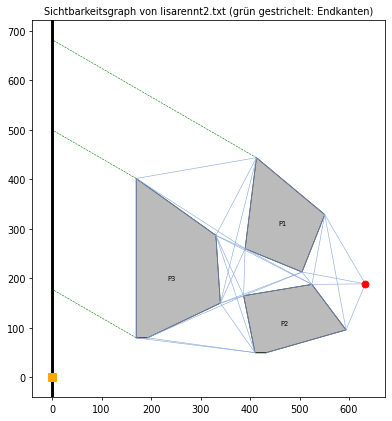

In [ ]:
def sichtbarkeitsgraph(haus, hindernisse):
    knoten = [haus]
    namen = ['L']
    for h in range(len(hindernisse)):
        for ecke in hindernisse[h]:
            knoten.append(ecke)
            namen.append('P%d' % (h + 1))
    nachbarn = []
    for i in range(len(knoten)):
        nachbarn.append([])
    for i in range(len(knoten)):
        for j in range(i + 1, len(knoten)):
            if frei(knoten[i], knoten[j], hindernisse):
                dauer = math.dist(knoten[i], knoten[j]) / V_LISA
                nachbarn[i].append((j, dauer))
                nachbarn[j].append((i, dauer))
    ende = {}
    for i in range(len(knoten)):
        if frei(knoten[i], zielpunkt(knoten[i]), hindernisse):
            ende[i] = verlust_ende(knoten[i])
    return knoten, namen, nachbarn, ende


for nr in range(1, 6):
    pruefungen = 0
    knoten, namen, nachbarn, ende = sichtbarkeitsgraph(beispiele[nr][0], beispiele[nr][1])
    print('lisarennt%d.txt: %2d Knoten, %3d Kanten, %2d Endkanten, %4d Prüfungen' %
          (nr, len(knoten), sum(len(n) for n in nachbarn) // 2, len(ende), pruefungen))

graph2 = sichtbarkeitsgraph(beispiele[2][0], beispiele[2][1])
fig, achse = plt.subplots(figsize=(7, 7))
zeichne(achse, beispiele[2][0], beispiele[2][1], 'Sichtbarkeitsgraph von lisarennt2.txt (grün gestrichelt: Endkanten)',
        graph=(graph2[0], graph2[2], graph2[3]))
plt.show()

Bei `n` Knoten gibt es etwa `n²/2` Paare, und jede Prüfung geht alle (etwa `n`) Kanten der Hindernisse durch: zusammen etwa `n³/2`
Rechenschritte. Bei 63 Knoten sind das gut 2000 Prüfungen, das geht schnell. Im Bild sieht man, dass auch die Seiten der Hindernisse
Kanten des Graphen sind (Lisa darf am Rand entlanglaufen). Nur drei Knoten haben eine freie Endkante; bei allen anderen versperrt ein
Hindernis die 30°-Strecke zur Straße.

## Schritt 5: Dijkstra und der beste Weg

`dijkstra` berechnet für jeden Knoten die kürzeste Laufzeit vom Haus und merkt sich in `vorher`, woher Lisa kam. Danach nehmen wir den
Knoten `i` mit Endkante, bei dem `zeit[i] + ende[i]` am kleinsten ist, und gehen mit `vorher` zurück zum Haus. `bericht` gibt aus,
was Lisa wissen will. Lisa muss um `7:30 Uhr - Verlust` losgehen.

In [ ]:
def dijkstra(nachbarn, start):
    zeit = [math.inf] * len(nachbarn)
    vorher = [None] * len(nachbarn)
    zeit[start] = 0
    warteschlange = [(0, start)]
    while warteschlange:
        t, u = heapq.heappop(warteschlange)
        if t > zeit[u]:
            continue                          # veralteter Eintrag, u wurde schon schneller erreicht
        for v, dauer in nachbarn[u]:
            if t + dauer < zeit[v]:
                zeit[v] = t + dauer
                vorher[v] = u
                heapq.heappush(warteschlange, (zeit[v], v))
    return zeit, vorher


def loese(haus, hindernisse):
    knoten, namen, nachbarn, ende = sichtbarkeitsgraph(haus, hindernisse)
    zeit, vorher = dijkstra(nachbarn, 0)
    bester = None
    for i in ende:
        if bester is None or zeit[i] + ende[i] < zeit[bester] + ende[bester]:
            bester = i
    weg = []
    i = bester
    while i is not None:
        weg.append(i)
        i = vorher[i]
    weg.reverse()
    punkte = [knoten[i] for i in weg] + [zielpunkt(knoten[bester])]
    wegnamen = [namen[i] for i in weg] + ['Straße']
    return punkte, wegnamen, zeit[bester] + ende[bester]


def uhrzeit(sekunden):
    h = int(sekunden // 3600)
    m = int(sekunden % 3600 // 60)
    s = sekunden - 3600 * h - 60 * m
    return ('%02d:%02d:%06.3f' % (h, m, s)).replace('.', ',')


def weglaenge(punkte):
    summe = 0
    for i in range(len(punkte) - 1):
        summe += math.dist(punkte[i], punkte[i + 1])
    return summe


def bericht(punkte, wegnamen, verlust):
    abfahrt = 7.5 * 3600                      # 7:30 Uhr in Sekunden
    laufzeit = weglaenge(punkte) / V_LISA
    print('Startzeit:   ', uhrzeit(abfahrt - verlust), 'Uhr')
    print('Treffpunkt:   (0, %.4f) um %s Uhr' % (punkte[-1][1], uhrzeit(abfahrt + punkte[-1][1] / V_BUS)))
    print('Weg:          %.4f m in %.3f s' % (weglaenge(punkte), laufzeit))
    teile = []
    for i in range(len(punkte)):
        teile.append('%s (%s, %s)' % (wegnamen[i], round(punkte[i][0], 4), round(punkte[i][1], 4)))
    print('Route:       ', ' > '.join(teile))


punkte1, wegnamen1, verlust1 = loese(beispiele[1][0], beispiele[1][1])
bericht(punkte1, wegnamen1, verlust1)

Startzeit:    07:27:59,981 Uhr
Treffpunkt:   (0, 718.8824) um 07:31:26,266 Uhr
Weg:          859.5188 m in 206.285 s
Route:        L (633, 189) > P1 (535, 410) > Straße (0, 718.8824)


Lisa läuft zuerst zur Spitze des Dreiecks und von dort unter 30° zur Straße. Sie darf um 7:27:59,981 Uhr losgehen, genau wie in den
Lösungshinweisen.

## Schritt 6: Alle Beispiele

lisarennt1.txt
Startzeit:    07:27:59,981 Uhr
Treffpunkt:   (0, 718.8824) um 07:31:26,266 Uhr
Weg:          859.5188 m in 206.285 s
Route:        L (633, 189) > P1 (535, 410) > Straße (0, 718.8824)

lisarennt2.txt
Startzeit:    07:28:08,991 Uhr
Treffpunkt:   (0, 500.1495) um 07:31:00,018 Uhr
Weg:          712.6106 m in 171.027 s
Route:        L (633, 189) > P1 (505, 213) > P1 (390, 260) > P3 (170, 402) > Straße (0, 500.1495)

lisarennt3.txt
Startzeit:    07:27:28,661 Uhr
Treffpunkt:   (0, 464.0089) um 07:30:55,681 Uhr
Weg:          862.5844 m in 207.020 s
Route:        L (479, 168) > P2 (519, 238) > P3 (599, 258) > P3 (499, 298) > P8 (426, 238) > P5 (390, 288) > P6 (352, 287) > P6 (291, 296) > Straße (0, 464.0089)

lisarennt4.txt
Startzeit:    07:26:55,975 Uhr
Treffpunkt:   (0, 992.3058) um 07:31:59,077 Uhr
Weg:          1262.9250 m in 303.102 s
Route:        L (856, 270) > P11 (900, 300) > P11 (900, 340) > P10 (896, 475) > Straße (0, 992.3058)

lisarennt5.txt
Startzeit:    07:27:54,92

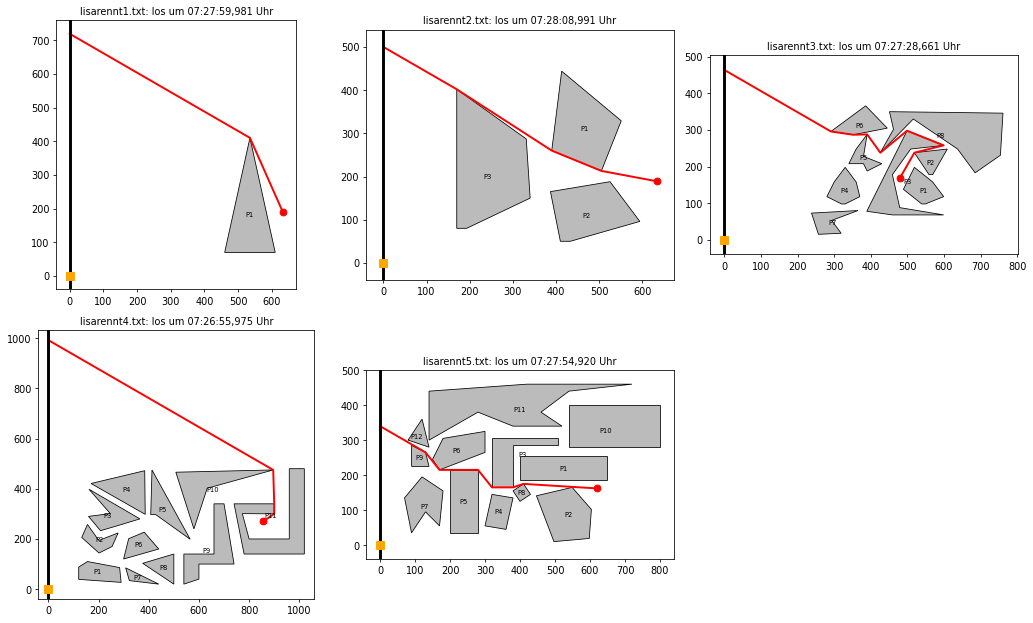

In [ ]:
ergebnisse = {}
for nr in range(1, 6):
    ergebnisse[nr] = loese(beispiele[nr][0], beispiele[nr][1])
    print('lisarennt%d.txt' % nr)
    bericht(ergebnisse[nr][0], ergebnisse[nr][1], ergebnisse[nr][2])
    print()

fig, achsen = plt.subplots(2, 3, figsize=(15, 9))
for nr in range(1, 6):
    zeichne(achsen[(nr - 1) // 3][(nr - 1) % 3], beispiele[nr][0], beispiele[nr][1],
            'lisarennt%d.txt: los um %s Uhr' % (nr, uhrzeit(7.5 * 3600 - ergebnisse[nr][2])), punkte=ergebnisse[nr][0])
achsen[1][2].axis('off')
plt.tight_layout()
plt.show()

**Vergleich mit den Lösungshinweisen** (Abschnitt 1.2):

| Beispiel | Startzeit (wir) | Startzeit (Hinweise) | Treffpunkt y (wir) | y (Hinweise) | Weglänge in m (wir) | (Hinweise) |
|----------|-----------------|----------------------|--------------------|--------------|---------------------|------------|
| `lisarennt1.txt` | 07:27:59,981 | 07:27:59,981 | 718,8824 | 718,8824 | 859,5188 | 859,5188 |
| `lisarennt2.txt` | 07:28:08,991 | 07:28:08,991 | 500,1495 | 500,1495 | 712,6106 | 712,6106 |
| `lisarennt3.txt` | 07:27:28,661 | 07:27:28,661 | 464,0089 | 464,0089 | 862,5844 | 862,5844 |
| `lisarennt4.txt` | 07:26:55,975 | 07:26:55,975 | 992,3058 | 992,3058 | 1262,9250 | 1262,9250 |
| `lisarennt5.txt` | 07:27:54,920 | 07:27:54,920 | 340,0555 | 340,0555 | 691,1964 | 691,1964 |

Startzeiten, Treffpunkte und Weglängen stimmen bei allen fünf Beispielen mit den Hinweisen überein, ebenso die Routen. Zwei
Kleinigkeiten:

- Bei `lisarennt5.txt` läuft die Route der Hinweise von `(280, 215)` über `(200, 215)` nach `(170, 215)`. Die drei Punkte liegen auf
  einer Geraden; wir gehen direkt von `(280, 215)` nach `(170, 215)`. Das ist derselbe Weg.
- Bei `lisarennt4.txt` geben die Hinweise die Dauer als „5.03,102 / 243,102“ an. 5 Minuten und 3,102 Sekunden sind aber 303,102
  Sekunden, so wie bei uns; die 243 ist ein Druckfehler.

## Schritt 7: Probe

**Ein Schiedsrichter.** `schiedsrichter` prüft einen Weg unabhängig von `frei`: Er beginnt am Haus und endet auf der Straße, und auf
jedem Stück liegen 1000 gleichmäßig verteilte Punkte in keinem Hindernis. Außerdem messen wir den Winkel des letzten Stücks.

In [ ]:
def schiedsrichter(haus, hindernisse, punkte):
    if punkte[0] != haus or abs(punkte[-1][0]) > EPS:
        return False
    for i in range(len(punkte) - 1):
        a, b = punkte[i], punkte[i + 1]
        for schritt in range(1, 1000):
            t = schritt / 1000
            p = (a[0] + t * (b[0] - a[0]), a[1] + t * (b[1] - a[1]))
            for ecken in hindernisse:
                if innen(p, ecken):
                    return False
    return True


for nr in range(1, 6):
    punkte = ergebnisse[nr][0]
    a, b = punkte[-2], punkte[-1]
    winkel = math.degrees(math.atan((b[1] - a[1]) / (a[0] - b[0])))
    print('lisarennt%d.txt: Schiedsrichter %s, letztes Stück unter %.4f Grad' %
          (nr, schiedsrichter(beispiele[nr][0], beispiele[nr][1], punkte), winkel))

lisarennt1.txt: Schiedsrichter True, letztes Stück unter 30.0000 Grad
lisarennt2.txt: Schiedsrichter True, letztes Stück unter 30.0000 Grad
lisarennt3.txt: Schiedsrichter True, letztes Stück unter 30.0000 Grad
lisarennt4.txt: Schiedsrichter True, letztes Stück unter 30.0000 Grad
lisarennt5.txt: Schiedsrichter True, letztes Stück unter 30.0000 Grad


**Andere Winkel?** Haben wir mit den 30°-Endkanten nichts verpasst, etwa einen Knoten, dessen 30°-Strecke versperrt ist, von dem aus
Lisa aber in einem anderen Winkel gut zur Straße käme? `raster` probiert von **jedem** Knoten aus **jeden** ganzzahligen Straßenpunkt
`(0, y)` mit `0 ≤ y < 1300`, zu dem die Strecke frei ist, und nimmt den kleinsten Verlust. Damit es nicht zu lange dauert, wird `frei`
nur aufgerufen, wenn der Punkt überhaupt besser wäre als der beste bisher.

In [ ]:
def raster(haus, hindernisse):
    knoten, namen, nachbarn, ende = sichtbarkeitsgraph(haus, hindernisse)
    zeit, vorher = dijkstra(nachbarn, 0)
    bester = math.inf
    for i in range(len(knoten)):
        for y in range(0, 1300):
            verlust = zeit[i] + verlust_direkt(knoten[i], y)
            if verlust < bester and frei(knoten[i], (0, y), hindernisse):
                bester = verlust
    return bester


raster_werte = {}
for nr in range(1, 6):
    pruefungen = 0
    raster_werte[nr] = raster(beispiele[nr][0], beispiele[nr][1])
    print('lisarennt%d.txt: Raster %.4f s, mit 30 Grad %.4f s, %5d Prüfungen' %
          (nr, raster_werte[nr], ergebnisse[nr][2], pruefungen))

lisarennt1.txt: Raster 120.0186 s, mit 30 Grad 120.0186 s,  2030 Prüfungen
lisarennt2.txt: Raster 111.0086 s, mit 30 Grad 111.0086 s,  1944 Prüfungen
lisarennt3.txt: Raster 151.3392 s, mit 30 Grad 151.3392 s, 26069 Prüfungen
lisarennt4.txt: Raster 184.0253 s, mit 30 Grad 184.0253 s, 13018 Prüfungen
lisarennt5.txt: Raster 125.0805 s, mit 30 Grad 125.0805 s, 27949 Prüfungen


Das Raster ist nie besser als unser Weg mit 30°-Endkante (bei ganzzahligen Treffpunkten kann es auch gar nicht ganz so gut sein), und
auf vier Stellen nach dem Komma gleich. Kein anderer Winkel und kein anderer letzter Knoten hilft.

## Für Neugierige: Warum genau 30°?

**Ein Beweis ohne Ableitungen.** Wir messen alles in „Lisa-Metern“: Was der Bus in einer Sekunde fährt, zählt halb so viel wie Lisas
Laufweg. Lisa läuft von `P` zum Straßenpunkt `Q`; der Bus fährt weiter bis zu einem weit entfernten Punkt `B` der Straße. Lisa und der
Bus zusammen brauchen die Zeit „Lisas Weg `PQ` + halbe Busstrecke `QB`“, und die soll so klein wie möglich sein (`B` liegt fest, also
ist das dasselbe, wie den Verlust klein zu machen).

Zeichne durch `B` eine Gerade `g`, die mit der Straße einen Winkel von 30° bildet und schräg nach rechts unten zu Lisa hin zeigt. Der
Abstand eines Straßenpunkts `Q` von `g` ist `QB · sin 30° = QB / 2`, genau die halbe Busstrecke. Also ist die Gesamtzeit
`PQ + (Abstand von Q zu g)`, und das ist mindestens der Abstand von `P` zu `g`: Der kürzeste Weg von `P` zu einer Geraden ist das Lot.
Gleichheit gilt, wenn `P`, `Q` und der Lotfußpunkt auf einer Geraden liegen, also wenn Lisa **senkrecht auf `g` zu** läuft. Diese
Richtung bildet mit der Senkrechten zur Straße einen Winkel von 30°.

**Andere Geschwindigkeiten.** Statt `1/2` steht dann `v_Lisa / v_Bus` da: Lisa läuft unter dem Winkel `α` mit `sin α = v_Lisa / v_Bus`.
Das ist ein Grenzfall des Brechungsgesetzes für Licht, das aus einem langsamen Stoff (Feld) in einen schnelleren (Straße) übergeht und
danach genau an der Grenze entlangläuft. Die Lösungshinweise leiten dasselbe mit einer Ableitung her.

**Eine Formel für die Endkanten.** Setzt man `s = x · tan 30°` ein, wird der Verlust auf dem letzten Stück von `(x, y)` aus zu
`(√3 · x - y) / (2 · v_Lisa)` (Formel 1.23 der Hinweise mit eingesetzten Geschwindigkeiten). Wir prüfen das an allen Ecken:

In [ ]:
groesste_abweichung = 0
for nr in range(1, 6):
    for ecken in beispiele[nr][1]:
        for x, y in ecken:
            formel = (math.sqrt(3) * x - y) / (2 * V_LISA)
            groesste_abweichung = max(groesste_abweichung, abs(formel - verlust_ende((x, y))))
print('größte Abweichung: %.1e Sekunden' % groesste_abweichung)

größte Abweichung: 5.7e-14 Sekunden


**Schnellere Sichtbarkeitsgraphen.** Unser Verfahren braucht etwa `n³` Schritte. Die Hinweise beschreiben ein Verfahren von Der-Tsai
Lee mit etwa `n² · log n` Schritten: Ein Strahl dreht sich einmal um jeden Knoten, und ein Suchbaum merkt sich, welche Kanten der Strahl
gerade schneidet, sortiert nach ihrer Entfernung. Sichtbar ist eine Ecke, wenn ihre Kante vorne steht. Für die Beispiele mit höchstens
63 Knoten lohnt sich der Aufwand nicht.

## Zum Schluss: Der kürzeste Weg mit MiniZinc

Die Geometrie (welche Knoten sich sehen) kann MiniZinc nicht gut berechnen; das überlassen wir Python. Den kürzesten Weg im fertigen
Sichtbarkeitsgraphen kann MiniZinc aber suchen. Wege beschreibt man als **Fluss**: Für jede Kante in jeder Richtung gibt es eine
Variable `x[e]` (1 = Lisa läuft sie). An jedem Knoten läuft Lisa so oft hinaus wie hinein, am Haus einmal mehr hinaus, an der Straße
(einem zusätzlichen Knoten `n`, zu dem die Endkanten führen) einmal mehr hinein. Neu ist `(v = 1)`: Ein Vergleich zählt in einer
Rechnung als 1, wenn er stimmt, sonst als 0.

Könnten zu den Variablen auch Kreise gehören, die nicht mit dem Weg zusammenhängen? Die Bedingungen würden sie erlauben, aber jeder
Kreis besteht aus Kanten mit positiver Laufzeit; ohne ihn ist der Verlust kleiner. Eine beste Lösung enthält also keinen. Die Zeiten
sind ganze Zahlen in Millisekunden. `fix(x[e])` in der Ausgabe ist der Wert der Variablen in der Lösung.
```minizinc
int: n;                                   % Knoten: 1 ist Lisas Haus, n ist die Straße
int: m;                                   % Zahl der gerichteten Kanten
array[1..m] of 1..n: von;
array[1..m] of 1..n: nach;
array[1..m] of int: zeit;                 % Millisekunden; bei Endkanten der Verlust (auch negativ)

array[1..m] of var 0..1: x;               % x[e] = 1: Lisa läuft über die Kante e

constraint forall(v in 1..n)(             % so oft hinaus wie hinein, am Haus einmal mehr hinaus, an der Straße einmal mehr hinein
    sum(e in 1..m where von[e] = v)(x[e]) - sum(e in 1..m where nach[e] = v)(x[e]) = (v = 1) - (v = n));

var int: verlust = sum(e in 1..m)(zeit[e] * x[e]);
solve minimize verlust;
output ["verlust = \(verlust) ms\n", concat(["\(von[e])->\(nach[e]) " | e in 1..m where fix(x[e]) = 1]), "\n"];
```

Die Datendatei erzeugt `als_dzn` aus dem Sichtbarkeitsgraphen. Knoten `i` von Python ist Knoten `i + 1` in MiniZinc.

In [ ]:
def als_dzn(haus, hindernisse):
    knoten, namen, nachbarn, ende = sichtbarkeitsgraph(haus, hindernisse)
    strasse = len(knoten) + 1
    von, nach, zeiten = [], [], []
    for i in range(len(knoten)):
        for j, dauer in nachbarn[i]:
            von.append(i + 1)
            nach.append(j + 1)
            zeiten.append(round(1000 * dauer))
        if i in ende:
            von.append(i + 1)
            nach.append(strasse)
            zeiten.append(round(1000 * ende[i]))
    return 'n = %d;\nm = %d;\nvon = %s;\nnach = %s;\nzeit = %s;' % (strasse, len(von), von, nach, zeiten)


print(als_dzn(beispiele[1][0], beispiele[1][1]))

n = 5;
m = 12;
von = [1, 1, 2, 2, 2, 2, 3, 3, 3, 4, 4, 4];
nach = [2, 3, 1, 3, 4, 5, 1, 2, 4, 2, 3, 5];
zeit = [58021, 29089, 58021, 83562, 83562, 61998, 29089, 83562, 36000, 83562, 36000, 87209];


**`lisarennt1.txt`** (HiGHS):

**Ausgabe:**

```
verlust = 120019 ms
1->2 2->5 
----------
==========
```

Knoten 1 ist das Haus, Knoten 2 die Spitze `(535, 410)` des Dreiecks, Knoten 5 die Straße: derselbe Weg wie in Schritt 5. Der Verlust
von 120,019 Sekunden ergibt wieder 7:27:59,981 Uhr (in Python 120,0186 Sekunden; MiniZinc rechnet mit gerundeten Millisekunden).

Wir lösen das Modell mit **HiGHS**, einem Solver für ganzzahlige lineare Optimierung, der bei MiniZinc dabei ist (Auswahl über
*Solver configuration*), und mit **CP-SAT**. Beide sind bei jedem Beispiel nach Sekundenbruchteilen fertig und beweisen dabei, dass es
nicht besser geht:

| Beispiel | Verlust MiniZinc (ms) | Verlust Python (s) |
|----------|-----------------------|--------------------|
| `lisarennt1.txt` | 120019 | 120,0186 |
| `lisarennt2.txt` | 111008 | 111,0086 |
| `lisarennt3.txt` | 151338 | 151,3392 |
| `lisarennt4.txt` | 184025 | 184,0253 |
| `lisarennt5.txt` | 125079 | 125,0805 |

Die Werte weichen durch das Runden der einzelnen Kanten um höchstens 1,5 Millisekunden ab. Rechnet man die Wege von MiniZinc
in Python nach, haben sie genau den Verlust aus der rechten Spalte (geprüft beim Erstellen des Notebooks).

Mit den anderen Solvern sieht es schlechter aus (gemessen beim Erstellen dieses Notebooks, Zeitlimit 30 Sekunden):

- **Chuffed** und **Gecode** lösen `lisarennt1.txt` und `lisarennt2.txt` in wenigen Sekunden. Bei `lisarennt3.txt` bis
  `lisarennt5.txt` werden beide in 30 Sekunden nicht fertig. Gecode findet gleich am Anfang einen Weg und danach keinen besseren mehr: Verlust 161,6 statt 151,3 Sekunden, 200,3 statt 184,0 und 130,4 statt 125,1. Chuffed hat nur sehr schlechte Lösungen mit mehr als 5800 Sekunden Verlust.

Woran liegt der Unterschied? Das Modell besteht nur aus Summen von 0/1-Variablen und einem Ziel, das eine Summe ist. Für solche Modelle
sind lineare Optimierer wie HiGHS gemacht: Beim Flussmodell eines kürzesten Weges ist schon die Lösung mit Kommazahlen ganzzahlig, der
Solver ist also mit einer einzigen Rechnung fertig. CP-SAT nutzt dieselbe Technik zusätzlich. Chuffed und Gecode probieren dagegen
Variablen nacheinander aus und merken spät, dass ein Umweg schlecht ist. Dijkstra bleibt das passende Werkzeug: Er nutzt aus, dass es
um **Wege** geht, und ist bei 63 Knoten sofort fertig.